** Antes de comenzar, debes haber revisado todo el material de los módulos 1 , 2 y 3 del curso.**

**Tomando como ejemplo lo realizado en los tutoriales, en esta tarea utilizarás las funciones de generación de datos de sklearn, como por ejemplo make_blobs, make_moons y make_circles, para crear conjuntos de entrenamiento que se adecuen a distintos modelos.**

**Genere múltiples conjuntos de datos (con sus respectivos subconjuntos de entrenamiento y prueba) y entrene sobre ellos al menos los siguientes tipos de modelo: SVM con kernel lineal, SVM con kernel RBF, SVM con kernel polinomial, SVM con kernel sigmoidal, MLP de 2 capas ocultas.**

**Para cada tipo de modelo, encuentre al menos un conjunto de datos donde este obtiene el mejor rendimiento de entre todos los modelos evaluados.**

**Para cada caso, explique el motivo por el cual el modelo ganador obtiene el mejor rendimiento. Utilice visualizaciones similares a las vistas en los tutoriales para justificar sus respuestas.**



In [43]:
# Importar librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

In [54]:
##Creamos los datos
from sklearn.datasets import make_circles, make_blobs, make_moons
rng = np.random.RandomState(0)

X1, y1 = make_circles(300,factor= 0.2, noise=0.1, random_state=0)
X2, y2 = make_moons(300, noise=0.1, random_state=0)
X3, y3= make_blobs(300,centers=2, cluster_std=1.5, random_state=0)
X4, y4 = make_blobs(60, centers=2, cluster_std=2.5, random_state=1)
X5 = rng.uniform(-3, 3, (60, 2))
y5 = (X5[:, 1] > X5[:, 0]**2 - 2).astype(int)
X6, y6 = make_blobs(300, centers=2, cluster_std=1.0, random_state=3)



##Separamos los datos

X1_train, X1_test, y1_train, y1_test=train_test_split(X1, y1, test_size=0.2, random_state=0)
X2_train, X2_test, y2_train, y2_test=train_test_split(X2, y2, test_size=0.2, random_state=0)
X3_train, X3_test, y3_train, y3_test=train_test_split(X3, y3, test_size=0.2, random_state=0)
X4_train, X4_test, y4_train, y4_test = train_test_split(X4, y4, test_size=0.3, random_state=0)
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.3, random_state=0)
X6_train, X6_test, y6_train, y6_test = train_test_split(X6, y6, test_size=0.3, random_state=0)

In [51]:
def visualize_classifier(model, X, Y, ax=None, cmap='rainbow'):
  ax = ax or plt.gca()
  ax.scatter(X[:, 0], X[:, 1], c=Y, s=30, cmap=cmap, clim=(Y.min(), Y.max()), zorder=3)
  ax.axis('tight')
  ax.axis('off')
  xlim = ax.get_xlim()
  ylim = ax.get_ylim()
  xx, yy = np.meshgrid(np.linspace(*xlim, num=200), np.linspace(*ylim, num=200))
  Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
  n_classes = len(np.unique(Y))
  ax.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(n_classes + 1) - 0.5, cmap=cmap, zorder=1)
  ax.set(xlim=xlim, ylim=ylim)

def train_y_eval(model, X_train, y_train, X_test, y_test):
  model.fit(X_train, y_train)
  acc_train=metrics.accuracy_score(y_train, model.predict(X_train))
  acc_test=metrics.accuracy_score(y_test, model.predict(X_test))
  print(f"Accuracy_train={acc_train}")
  print(f"Accuracy_test={acc_test}")
  return acc_test

Accuracy_train=0.5291666666666667
Accuracy_test=0.38333333333333336
Accuracy_train=0.8666666666666667
Accuracy_test=0.9
Accuracy_train=0.875
Accuracy_test=0.9333333333333333
Accuracy_train=1.0
Accuracy_test=1.0
Accuracy_train=0.7142857142857143
Accuracy_test=0.6666666666666666
Accuracy_train=0.9952380952380953
Accuracy_test=1.0


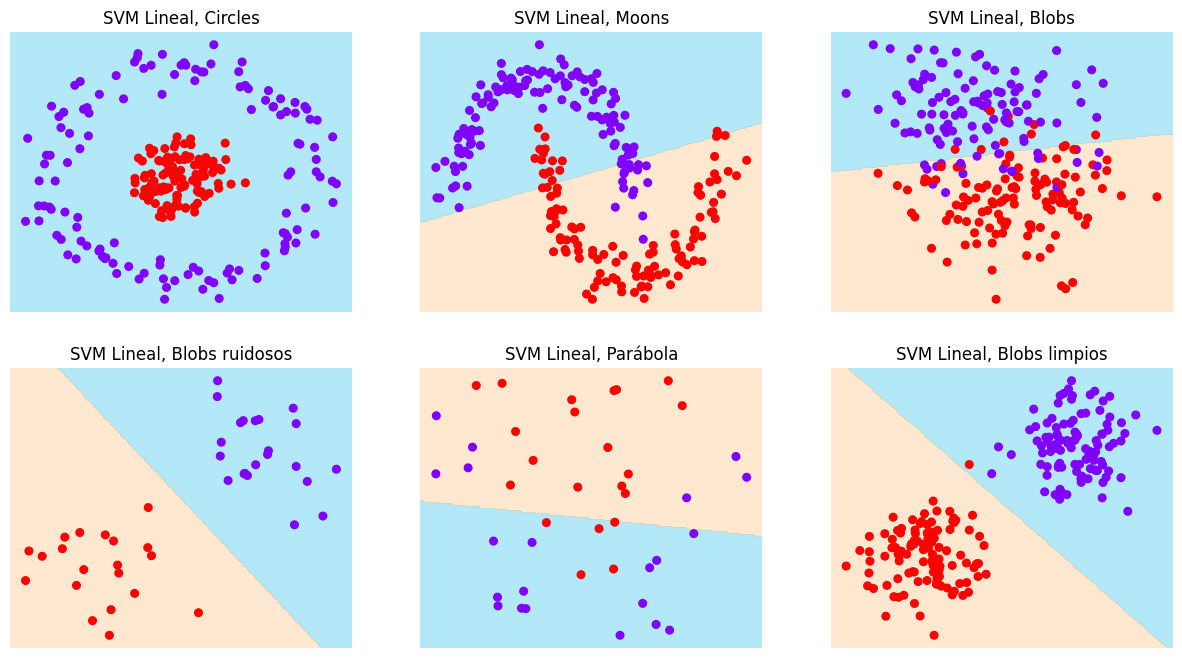

In [57]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn import metrics

##Modelo SVM con Kernel Lineal

Klineal=make_pipeline(StandardScaler(), SVC(kernel="linear"))

fig, axes= plt.subplots(2,3, figsize=(15,8))
axes = axes.ravel()

acclineal_1= train_y_eval(Klineal, X1_train, y1_train, X1_test, y1_test)
visualize_classifier(Klineal, X1_train, y1_train, ax=axes[0])
axes[0].set_title("SVM Lineal, Circles")

acclineal_2= train_y_eval(Klineal, X2_train, y2_train, X2_test, y2_test)
visualize_classifier(Klineal, X2_train, y2_train, ax=axes[1])
axes[1].set_title("SVM Lineal, Moons")

acclineal_3= train_y_eval(Klineal, X3_train, y3_train, X3_test, y3_test)
visualize_classifier(Klineal, X3_train, y3_train, ax=axes[2])
axes[2].set_title("SVM Lineal, Blobs")

acclineal_4 = train_y_eval(Klineal, X4_train, y4_train, X4_test, y4_test)
visualize_classifier(Klineal, X4_train, y4_train, ax=axes[3])
axes[3].set_title("SVM Lineal, Blobs ruidosos")

acclineal_5 = train_y_eval(Klineal, X5_train, y5_train, X5_test, y5_test)
visualize_classifier(Klineal, X5_train, y5_train, ax=axes[4])
axes[4].set_title("SVM Lineal, Parábola")

acclineal_6 = train_y_eval(Klineal, X6_train, y6_train, X6_test, y6_test)
visualize_classifier(Klineal, X6_train, y6_train, ax=axes[5])
axes[5].set_title("SVM Lineal, Blobs limpios")
plt.show()

Accuracy_train=1.0
Accuracy_test=1.0
Accuracy_train=0.9958333333333333
Accuracy_test=1.0
Accuracy_train=0.9083333333333333
Accuracy_test=0.95
Accuracy_train=1.0
Accuracy_test=1.0
Accuracy_train=0.9761904761904762
Accuracy_test=1.0
Accuracy_train=0.9952380952380953
Accuracy_test=1.0


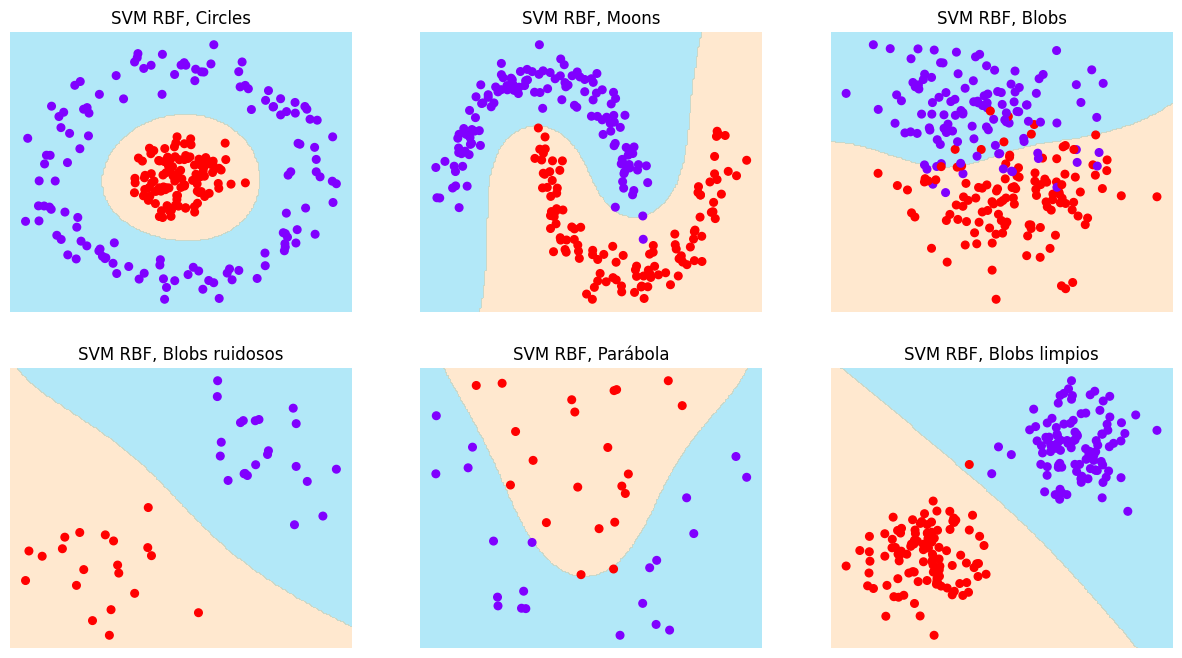

In [58]:
##Modelo SVM con Kernel RBF

rbf=make_pipeline(StandardScaler(), SVC(kernel="rbf"))

fig, axes= plt.subplots(2,3, figsize=(15,8))
axes = axes.ravel()

accrbf_1= train_y_eval(rbf, X1_train, y1_train, X1_test, y1_test)
visualize_classifier(rbf, X1_train, y1_train, ax=axes[0])
axes[0].set_title("SVM RBF, Circles")

accrbf_2= train_y_eval(rbf, X2_train, y2_train, X2_test, y2_test)
visualize_classifier(rbf, X2_train, y2_train, ax=axes[1])
axes[1].set_title("SVM RBF, Moons")

accrbf_3= train_y_eval(rbf, X3_train, y3_train, X3_test, y3_test)
visualize_classifier(rbf, X3_train, y3_train, ax=axes[2])
axes[2].set_title("SVM RBF, Blobs")

accrbf_4 = train_y_eval(rbf, X4_train, y4_train, X4_test, y4_test)
visualize_classifier(rbf, X4_train, y4_train, ax=axes[3])
axes[3].set_title("SVM RBF, Blobs ruidosos")

accrbf_5 = train_y_eval(rbf, X5_train, y5_train, X5_test, y5_test)
visualize_classifier(rbf, X5_train, y5_train, ax=axes[4])
axes[4].set_title("SVM RBF, Parábola")

accrbf_6 = train_y_eval(rbf, X6_train, y6_train, X6_test, y6_test)
visualize_classifier(rbf, X6_train, y6_train, ax=axes[5])
axes[5].set_title("SVM RBF, Blobs limpios")
plt.show()

Accuracy_train=0.5291666666666667
Accuracy_test=0.38333333333333336
Accuracy_train=0.9125
Accuracy_test=0.9
Accuracy_train=0.8708333333333333
Accuracy_test=0.8833333333333333
Accuracy_train=0.9761904761904762
Accuracy_test=1.0
Accuracy_train=0.8333333333333334
Accuracy_test=0.8888888888888888
Accuracy_train=0.9952380952380953
Accuracy_test=1.0


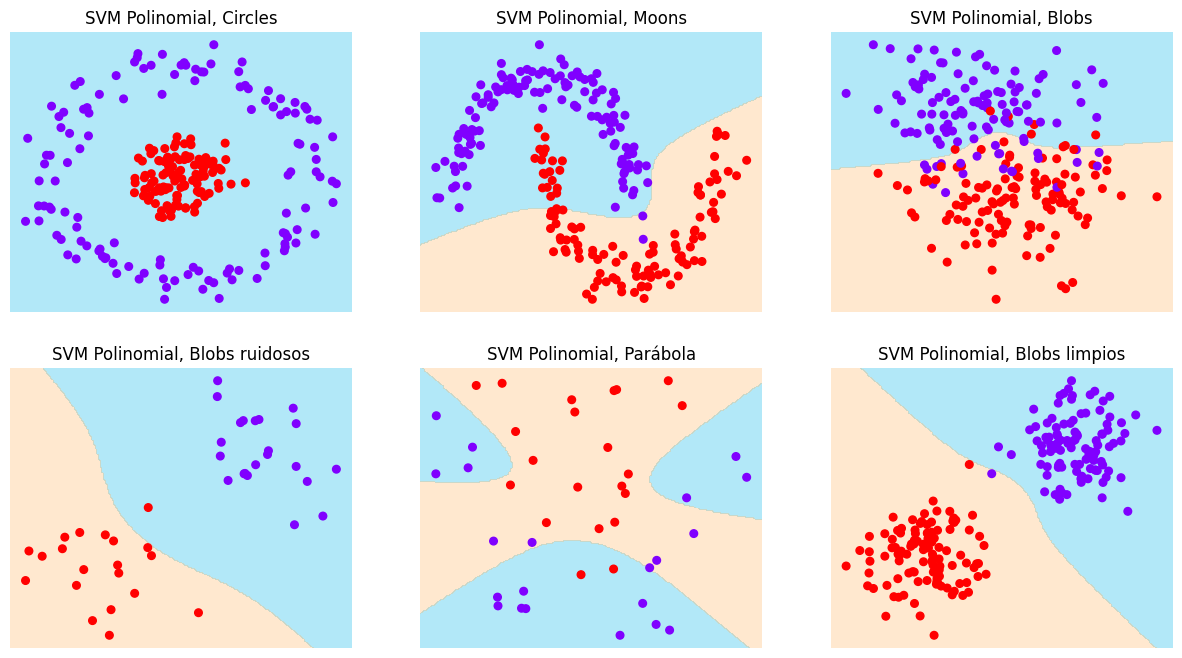

In [59]:
##Modelo SVM con Kernel Polinomial

poly=make_pipeline(StandardScaler(), SVC(kernel="poly", degree=3))

fig, axes= plt.subplots(2,3, figsize=(15,8))
axes = axes.ravel()

accpoly_1= train_y_eval(poly, X1_train, y1_train, X1_test, y1_test)
visualize_classifier(poly, X1_train, y1_train, ax=axes[0])
axes[0].set_title("SVM Polinomial, Circles")

accpoly_2= train_y_eval(poly, X2_train, y2_train, X2_test, y2_test)
visualize_classifier(poly, X2_train, y2_train, ax=axes[1])
axes[1].set_title("SVM Polinomial, Moons")

accpoly_3= train_y_eval(poly, X3_train, y3_train, X3_test, y3_test)
visualize_classifier(poly, X3_train, y3_train, ax=axes[2])
axes[2].set_title("SVM Polinomial, Blobs")

accpoly_4 = train_y_eval(poly, X4_train, y4_train, X4_test, y4_test)
visualize_classifier(poly, X4_train, y4_train, ax=axes[3])
axes[3].set_title("SVM Polinomial, Blobs ruidosos")

accpoly_5 = train_y_eval(poly, X5_train, y5_train, X5_test, y5_test)
visualize_classifier(poly, X5_train, y5_train, ax=axes[4])
axes[4].set_title("SVM Polinomial, Parábola")

accpoly_6 = train_y_eval(poly, X6_train, y6_train, X6_test, y6_test)
visualize_classifier(poly, X6_train, y6_train, ax=axes[5])
axes[5].set_title("SVM Polinomial, Blobs limpios")
plt.show()

Accuracy_train=0.5625
Accuracy_test=0.5666666666666667
Accuracy_train=0.6916666666666667
Accuracy_test=0.6666666666666666
Accuracy_train=0.8416666666666667
Accuracy_test=0.8666666666666667
Accuracy_train=1.0
Accuracy_test=1.0
Accuracy_train=0.7380952380952381
Accuracy_test=0.6111111111111112
Accuracy_train=0.9952380952380953
Accuracy_test=1.0


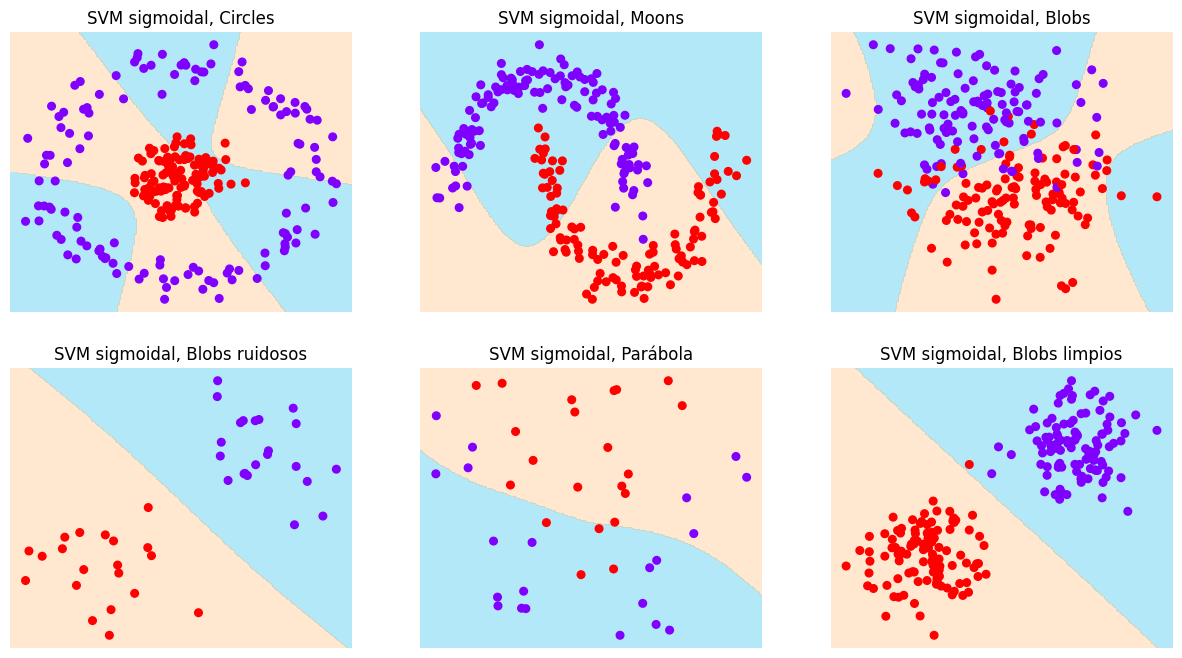

In [60]:
##Modelo SVM con Kernel sigmoidal

sigmoid=make_pipeline(StandardScaler(), SVC(kernel="sigmoid"))

fig, axes= plt.subplots(2,3, figsize=(15,8))
axes = axes.ravel()

accsig_1= train_y_eval(sigmoid, X1_train, y1_train, X1_test, y1_test)
visualize_classifier(sigmoid, X1_train, y1_train, ax=axes[0])
axes[0].set_title("SVM sigmoidal, Circles")

accsig_2= train_y_eval(sigmoid, X2_train, y2_train, X2_test, y2_test)
visualize_classifier(sigmoid, X2_train, y2_train, ax=axes[1])
axes[1].set_title("SVM sigmoidal, Moons")

accsig_3= train_y_eval(sigmoid, X3_train, y3_train, X3_test, y3_test)
visualize_classifier(sigmoid, X3_train, y3_train, ax=axes[2])
axes[2].set_title("SVM sigmoidal, Blobs")

accsig_4 = train_y_eval(sigmoid, X4_train, y4_train, X4_test, y4_test)
visualize_classifier(sigmoid, X4_train, y4_train, ax=axes[3])
axes[3].set_title("SVM sigmoidal, Blobs ruidosos")

accsig_5 = train_y_eval(sigmoid, X5_train, y5_train, X5_test, y5_test)
visualize_classifier(sigmoid, X5_train, y5_train, ax=axes[4])
axes[4].set_title("SVM sigmoidal, Parábola")

accsig_6 = train_y_eval(sigmoid, X6_train, y6_train, X6_test, y6_test)
visualize_classifier(sigmoid, X6_train, y6_train, ax=axes[5])
axes[5].set_title("SVM sigmoidal, Blobs limpios")
plt.show()

Accuracy_train=1.0
Accuracy_test=1.0
Accuracy_train=0.9958333333333333
Accuracy_test=1.0
Accuracy_train=0.9
Accuracy_test=0.9333333333333333
Accuracy_train=1.0
Accuracy_test=1.0
Accuracy_train=1.0
Accuracy_test=0.9444444444444444
Accuracy_train=1.0
Accuracy_test=1.0


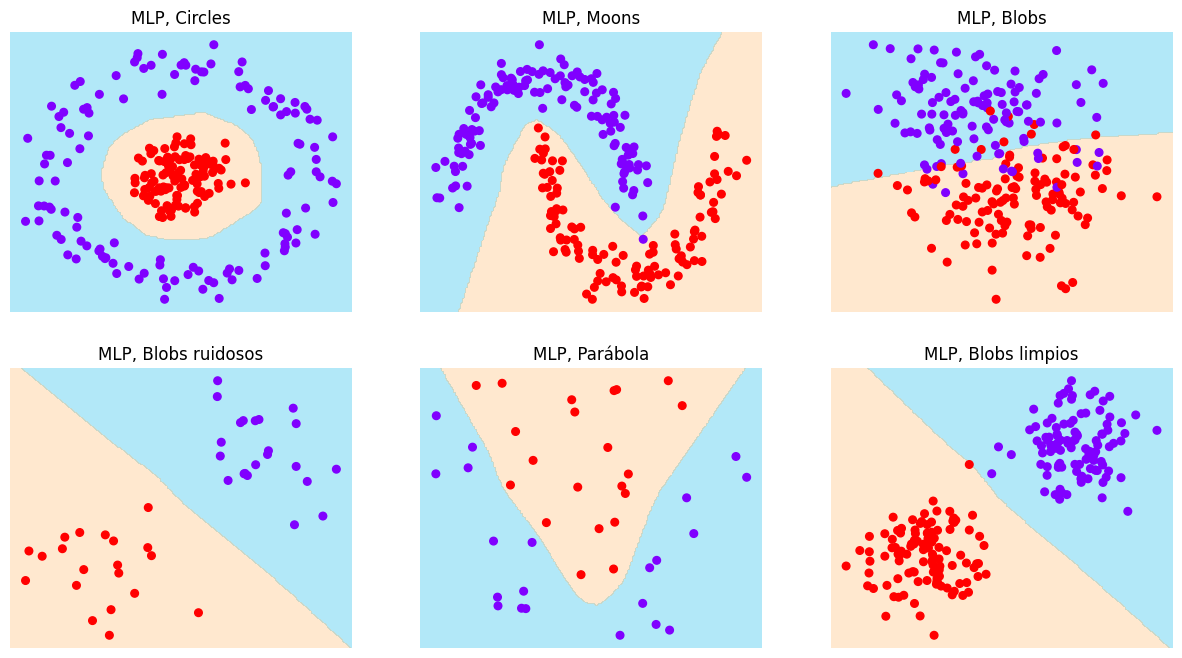

In [61]:
##Modelo MLP
from sklearn.neural_network import MLPClassifier

mlp=make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20,20), max_iter=2000, random_state=0))

fig, axes= plt.subplots(2,3, figsize=(15,8))
axes = axes.ravel()

accmlp_1= train_y_eval(mlp, X1_train, y1_train, X1_test, y1_test)
visualize_classifier(mlp, X1_train, y1_train, ax=axes[0])
axes[0].set_title("MLP, Circles")

accmlp_2= train_y_eval(mlp, X2_train, y2_train, X2_test, y2_test)
visualize_classifier(mlp, X2_train, y2_train, ax=axes[1])
axes[1].set_title("MLP, Moons")

accmlp_3= train_y_eval(mlp, X3_train, y3_train, X3_test, y3_test)
visualize_classifier(mlp, X3_train, y3_train, ax=axes[2])
axes[2].set_title("MLP, Blobs")

accmlp_4 = train_y_eval(mlp, X4_train, y4_train, X4_test, y4_test)
visualize_classifier(mlp, X4_train, y4_train, ax=axes[3])
axes[3].set_title("MLP, Blobs ruidosos")

accmlp_5 = train_y_eval(mlp, X5_train, y5_train, X5_test, y5_test)
visualize_classifier(mlp, X5_train, y5_train, ax=axes[4])
axes[4].set_title("MLP, Parábola")

accmlp_6 = train_y_eval(mlp, X6_train, y6_train, X6_test, y6_test)
visualize_classifier(mlp, X6_train, y6_train, ax=axes[5])
axes[5].set_title("MLP, Blobs limpios")

plt.show()

En conclusión, utilizamos tres data sets distintos para probar los modelos, en este caso, al observar el Accuracy para la etapa de test y ver qué tan bien generalizan los modelos, vemos como el modelo RBF y MLP presentan un Accuracy de 1 para los data sets de circles (1) y moons (2), mientras que el modelo RBF presenta el mayor accuracy en el data set blobs (3) y el dataset 5. Ante esto, concluimos que el modelo RBF es el que mejor generaliza.

Para el dataset de Circles (1), el Kernel RBF que mide la similitud en los puntos según su distancia es capaz de crear regiones circulares pues estos se encuentran agrupados, lo cual también realiza el modelo MLP al combinar varias fronteras hasta formar una región cerrada.

Para el caso del dataset Moons (2), RBF y MLP siguen la curvatura de la figura, logrando categorizar correctamente los datos, mientras que un modelo lineal traza una recta que deja mal clasificados aquellos puntos que se encuentran cerca entre sí.

Por su lado, en el data frame Blobs, que las clases sean separables mejora la predicción del modelo lineal, empatando con el modelo MLP, pero aun el modelo RBF logra predecir mejor los resultados, mostrando una leve diferencia explicada por los puntos que se solapan, donde el modelo RBF muestra un mejor rendimiento al contar con una frontera más flexible.

Con respecto al data set de blobs ruidosos (5), vemos como los 5 modelos empatan al igual que en el data set 6, donde vemos como las clases son fácilmente separables con un vacío entre los datos, por lo que los distintos modelos logran encontrar una frontera simple que clasifica correctamente los datos.

